# EcoSort: AI-Enabled Waste Management Assistant

### Project Overview

An AI-enabled waste management assistant that combines computer vision, natural language processing, and Retrieval-Augmented Generation (RAG) to identify waste materials and provide recycling and disposal guidance

### Part 1: Dataset Exploration and Preparation

In [1]:
! pip install tensorflow

In [1]:
# Import necessary libraries
import os
import random
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import json
import re
from pathlib import Path
from PIL import Image
from collections import Counter

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)
random.seed(42)

Dataset location: c:\Users\kevin\OneDrive\Documents\MS_DS_Projects\Projects\ecosort-waste-management\data\realwaste-main\RealWaste

Number of waste categories: 9
Waste categories: ['Cardboard', 'Food Organics', 'Glass', 'Metal', 'Miscellaneous Trash', 'Paper', 'Plastic', 'Textile Trash', 'Vegetation']

Total images found: 4752


,Category,Image Count
0,Cardboard,461
1,Food Organics,411
2,Glass,420
3,Metal,790
4,Miscellaneous Trash,495
5,Paper,500
6,Plastic,921
7,Textile Trash,318
8,Vegetation,436


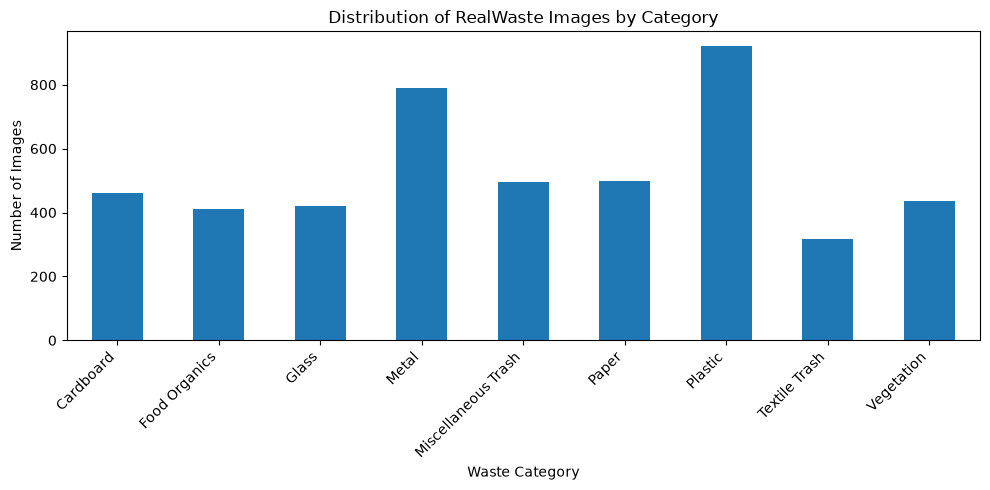


Readable images: 4752
Unreadable or corrupted images: 0

Image resolution statistics:


,width,height
count,4752.0,4752.0
mean,524.0,524.0
std,0.0,0.0
min,524.0,524.0
25%,524.0,524.0
50%,524.0,524.0
75%,524.0,524.0
max,524.0,524.0



Image formats:
format
JPEG    4752
Name: count, dtype: int64

Images by category successfully inspected:


category
Plastic                921
Metal                  790
Paper                  500
Miscellaneous Trash    495
Cardboard              461
Vegetation             436
Glass                  420
Food Organics          411
Textile Trash          318
Name: count, dtype: int64

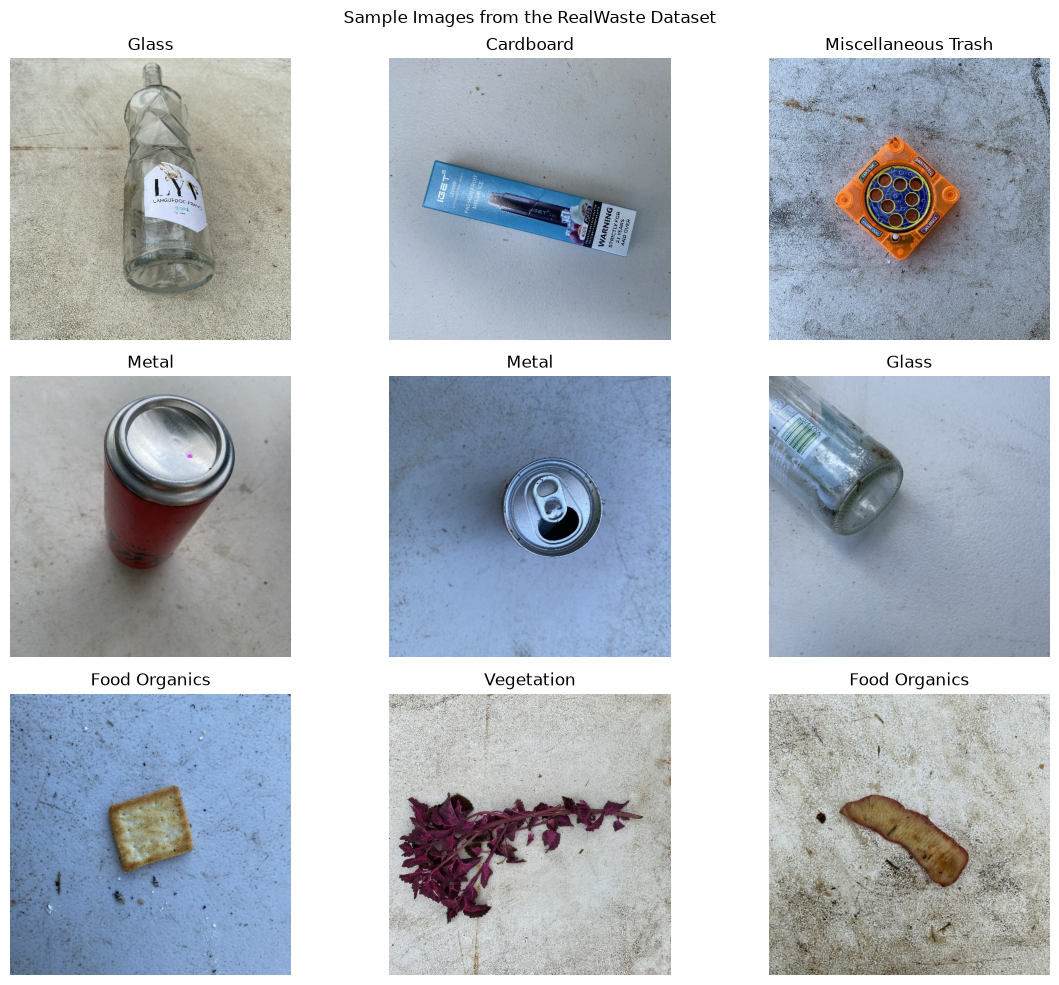

In [2]:
# 1. Locate the RealWaste dataset
PROJECT_DIR = Path.cwd()

possible_paths = [
    PROJECT_DIR / "realwaste-main" / "RealWaste",
    PROJECT_DIR / "RealWaste",
    PROJECT_DIR / "realwaste" / "RealWaste",
]

DATASET_DIR = next(
    (path for path in possible_paths if path.is_dir()),
    None
)

# Search subfolders if the dataset is not in the expected locations
if DATASET_DIR is None:
    for path in PROJECT_DIR.rglob("RealWaste"):
        if path.is_dir() and any(item.is_dir() for item in path.iterdir()):
            DATASET_DIR = path
            break

if DATASET_DIR is None:
    raise FileNotFoundError(
        "RealWaste dataset folder not found. "
        "Update possible_paths to point to your RealWaste directory."
    )

print("Dataset location:", DATASET_DIR)

# 2. Explore the dataset structure
categories = sorted(
    folder.name
    for folder in DATASET_DIR.iterdir()
    if folder.is_dir()
)

print("\nNumber of waste categories:", len(categories))
print("Waste categories:", categories)

# 3. Count images in each category
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

image_paths = []
category_counts = {}

for category in categories:
    category_dir = DATASET_DIR / category

    files = [
        path for path in category_dir.rglob("*")
        if path.is_file() and path.suffix.lower() in image_extensions
    ]

    category_counts[category] = len(files)
    image_paths.extend((path, category) for path in files)

category_df = pd.DataFrame(
    list(category_counts.items()),
    columns=["Category", "Image Count"]
)

print("\nTotal images found:", len(image_paths))
display(category_df)

# 4. Visualize the distribution of waste categories
if not category_df.empty:
    category_df.plot(
        x="Category",
        y="Image Count",
        kind="bar",
        legend=False,
        figsize=(10, 5)
    )

    plt.title("Distribution of RealWaste Images by Category")
    plt.xlabel("Waste Category")
    plt.ylabel("Number of Images")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

# 5. Inspect image characteristics
image_info = []
corrupted_images = []

for path, category in image_paths:
    try:
        with Image.open(path) as img:
            img.verify()

        # Reopen the image after verify() before reading its properties
        with Image.open(path) as img:
            image_info.append({
                "category": category,
                "width": img.width,
                "height": img.height,
                "format": img.format
            })

    except Exception as error:
        corrupted_images.append(str(path))

# Convert the collected information into DataFrames
image_info = pd.DataFrame(
    image_info,
    columns=["category", "width", "height", "format"]
)

print("\nReadable images:", len(image_info))
print("Unreadable or corrupted images:", len(corrupted_images))

if not image_info.empty:
    print("\nImage resolution statistics:")
    display(image_info[["width", "height"]].describe())

    print("\nImage formats:")
    print(image_info["format"].value_counts())

    print("\nImages by category successfully inspected:")
    display(image_info["category"].value_counts())
else:
    print(
        "\nNo readable images were recorded. "
        "Check the dataset location and image files."
    )

# 6. Display sample images to inspect quality and backgrounds
if image_paths:
    random.seed(42)
    samples = random.sample(image_paths, min(9, len(image_paths)))

    fig, axes = plt.subplots(3, 3, figsize=(12, 10))
    axes = axes.flatten()

    for ax, (path, category) in zip(axes, samples):
        try:
            with Image.open(path) as img:
                ax.imshow(img.convert("RGB"))
            ax.set_title(category)
        except Exception:
            ax.set_title(f"{category}\nImage could not be opened")

        ax.axis("off")

    for ax in axes[len(samples):]:
        ax.axis("off")

    plt.suptitle("Sample Images from the RealWaste Dataset")
    plt.tight_layout()
    plt.show()
else:
    print("No image paths available for visual inspection.")

### 1.2. Explore Text Datasets

Dataset location: c:\Users\kevin\OneDrive\Documents\MS_DS_Projects\Projects\ecosort-waste-management\data\waste_descriptions.csv

Dataset shape: (5000, 5)
Number of rows: 5000
Number of columns: 5

Column names:
['description', 'category', 'disposal_instruction', 'common_confusion', 'material_composition']

First five records:


,description,category,disposal_instruction,common_confusion,material_composition
0,soiled silver tablecloth,Textile Trash,Look for textile recycling programs in your area.,NaN,"Fabric made from natural or synthetic fibers, ..."
1,folded glass bottle leaking,Glass,"Remove caps, lids, and corks before recycling.",NaN,"Silica-based material, may contain additives f..."
2,large Supermarket vegetable waste with food re...,Food Organics,"If no compost available, place in general waste.",NaN,Biodegradable matter derived from plant or ani...
3,intact floral carpet piece,Textile Trash,Look for textile recycling programs in your area.,NaN,"Fabric made from natural or synthetic fibers, ..."
4,empty fun-sized purple apple core,Food Organics,Keep separate from recyclable materials.,Meat and dairy products may be restricted in s...,Biodegradable matter derived from plant or ani...



Column data types:
description             str
category                str
disposal_instruction    str
common_confusion        str
material_composition    str
dtype: object

Missing values per column:
description                0
category                   0
disposal_instruction       0
common_confusion        2504
material_composition       0
dtype: int64

Number of duplicate rows: 7

Text column: description
Category column: category

Text statistics:
Descriptions: 5000
Total word tokens: 25241
Unique words in vocabulary: 309
Average words per description: 4.85
Shortest description (words): 1
Longest description (words): 10

10 sample descriptions:


,category,description
0,Textile Trash,soiled silver tablecloth
1,Glass,folded glass bottle leaking
2,Food Organics,large Supermarket vegetable waste with food re...
3,Textile Trash,intact floral carpet piece
4,Food Organics,empty fun-sized purple apple core
5,Plastic,wrinkled pink takeout container with product r...
6,Glass,broken glass container
7,Vegetation,clean red grass clippings
8,Cardboard,Designer egg carton
9,Metal,wrinkled metal cutlery with food residue



20 most frequent words:


,Word,Frequency
0,with,727
1,sized,534
2,glass,424
3,empty,348
4,bottle,342
5,food,316
6,paper,316
7,box,313
8,residue,309
9,plastic,280



Category distribution:


,Category,Description Count,Percentage
0,Vegetation,600,12.00
1,Textile Trash,586,11.72
2,Cardboard,584,11.68
3,Miscellaneous Trash,578,11.56
4,Plastic,569,11.38
5,Glass,551,11.02
6,Food Organics,518,10.36
7,Metal,508,10.16
8,Paper,506,10.12


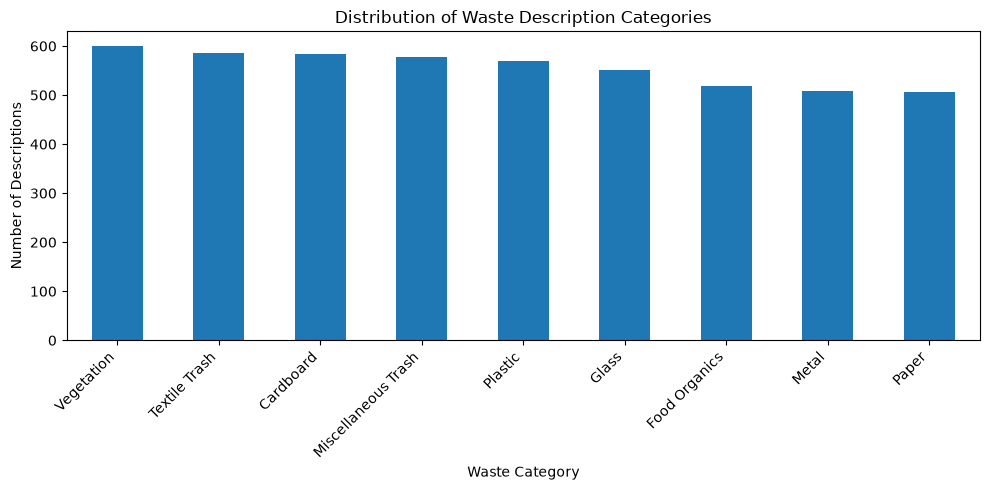


Description length by category:


,count,mean,median,min,max
category,,,,,
Cardboard,584,4.90,5.0,2,9
Food Organics,518,4.91,5.0,2,9
Glass,551,4.86,5.0,2,10
Metal,508,4.84,5.0,1,9
Miscellaneous Trash,578,4.98,5.0,2,10
Paper,506,4.54,4.5,1,10
Plastic,569,4.86,5.0,2,9
Textile Trash,586,5.05,5.0,1,10
Vegetation,600,4.71,5.0,1,9


In [3]:
# 1. Locate and load the CSV file
possible_paths = [
    Path.cwd() / "waste_descriptions.csv",
    Path.cwd() / "data" / "waste_descriptions.csv",
]

csv_path = next(
    (path for path in possible_paths if path.is_file()),
    None
)

# Search subfolders if the file is not in the expected locations
if csv_path is None:
    matches = list(Path.cwd().rglob("waste_descriptions.csv"))
    if matches:
        csv_path = matches[0]

if csv_path is None:
    raise FileNotFoundError(
        "Could not find waste_descriptions.csv. "
        "Place it in the notebook folder or update the file path."
    )

waste_df = pd.read_csv(csv_path)

print("Dataset location:", csv_path)
print("\nDataset shape:", waste_df.shape)
print("Number of rows:", len(waste_df))
print("Number of columns:", len(waste_df.columns))

# 2. Explore the dataset structure
print("\nColumn names:")
print(waste_df.columns.tolist())

print("\nFirst five records:")
display(waste_df.head())

print("\nColumn data types:")
print(waste_df.dtypes)

print("\nMissing values per column:")
print(waste_df.isnull().sum())

print("\nNumber of duplicate rows:", waste_df.duplicated().sum())

# 3. Identify the text-description and category columns
# This makes the code adaptable to common column-name variations.
normalized_columns = {
    col: re.sub(r"[^a-z0-9]", "", str(col).lower())
    for col in waste_df.columns
}

text_candidates = [
    "description", "text", "wastedescription",
    "itemdescription", "sentence"
]
category_candidates = [
    "category", "label", "class", "wastecategory",
    "wastetype", "target"
]

text_col = next(
    (
        col for candidate in text_candidates
        for col, normalized in normalized_columns.items()
        if normalized == candidate
    ),
    None
)

category_col = next(
    (
        col for candidate in category_candidates
        for col, normalized in normalized_columns.items()
        if normalized == candidate
    ),
    None
)

if text_col is None:
    raise ValueError(
        "Could not identify the description column. "
        "Check the printed column names and set text_col manually."
    )

if category_col is None:
    raise ValueError(
        "Could not identify the category column. "
        "Check the printed column names and set category_col manually."
    )

print("\nText column:", text_col)
print("Category column:", category_col)

# 4. Examine the text descriptions
descriptions = waste_df[text_col].fillna("").astype(str)

word_lists = [
    re.findall(r"\b[a-zA-Z]+\b", description.lower())
    for description in descriptions
]

all_words = [
    word
    for words in word_lists
    for word in words
]

vocabulary = set(all_words)
word_counts = Counter(all_words)

description_lengths = descriptions.str.split().str.len()

print("\nText statistics:")
print("Descriptions:", len(descriptions))
print("Total word tokens:", len(all_words))
print("Unique words in vocabulary:", len(vocabulary))
print("Average words per description:", round(description_lengths.mean(), 2))
print("Shortest description (words):", description_lengths.min())
print("Longest description (words):", description_lengths.max())

print("\n10 sample descriptions:")
display(waste_df[[category_col, text_col]].head(10))

print("\n20 most frequent words:")
display(
    pd.DataFrame(
        word_counts.most_common(20),
        columns=["Word", "Frequency"]
    )
)

# 5. Understand the distribution of waste categories
category_counts = (
    waste_df[category_col]
    .fillna("Missing category")
    .value_counts()
    .rename_axis("Category")
    .reset_index(name="Description Count")
)

category_counts["Percentage"] = (
    category_counts["Description Count"]
    / len(waste_df) * 100
).round(2)

print("\nCategory distribution:")
display(category_counts)

category_counts.plot(
    x="Category",
    y="Description Count",
    kind="bar",
    legend=False,
    figsize=(10, 5)
)

plt.title("Distribution of Waste Description Categories")
plt.xlabel("Waste Category")
plt.ylabel("Number of Descriptions")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# 6. Compare description lengths across categories
length_summary = waste_df[[category_col, text_col]].copy()
length_summary["Word Count"] = (
    length_summary[text_col]
    .fillna("")
    .astype(str)
    .str.split()
    .str.len()
)

print("\nDescription length by category:")
display(
    length_summary.groupby(category_col)["Word Count"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

Policy file location: c:\Users\kevin\OneDrive\Documents\MS_DS_Projects\Projects\ecosort-waste-management\data\waste_policy_documents.json

Number of documents/records: 14
Number of columns: 6

Column names:
['policy_id', 'policy_type', 'categories_covered', 'effective_date', 'document_text', 'jurisdiction']

First five records:


,policy_id,policy_type,categories_covered,effective_date,document_text,jurisdiction
0,1,Textile Trash Recycling Guidelines,[Textile Trash],2023-11-04,TEXTILE RECYCLING GUIDELINES\n\nAcceptable Ite...,Metro City
1,2,Glass Recycling Guidelines,[Glass],2023-01-24,GLASS RECYCLING GUIDELINES\n\nAcceptable Items...,Metro City
2,3,Food Organics Recycling Guidelines,[Food Organics],2023-05-08,FOOD ORGANICS RECYCLING GUIDELINES\n\nAcceptab...,Metro City
3,4,Plastic Recycling Guidelines,[Plastic],2023-04-05,PLASTIC RECYCLING GUIDELINES\n\nAcceptable Ite...,Metro City
4,5,Vegetation Recycling Guidelines,[Vegetation],2023-12-04,VEGETATION RECYCLING GUIDELINES\n\nAcceptable ...,Metro City



Data types:
policy_id              int64
policy_type              str
categories_covered    object
effective_date           str
document_text            str
jurisdiction             str
dtype: object

Missing values per column:
policy_id             0
policy_type           0
categories_covered    0
effective_date        0
document_text         0
jurisdiction          0
dtype: int64

Original JSON structure:
Top-level structure: list
First item type: dict
First item's keys: ['policy_id', 'policy_type', 'categories_covered', 'effective_date', 'document_text', 'jurisdiction']

Text-like columns: ['policy_type', 'categories_covered', 'effective_date', 'document_text', 'jurisdiction']

Column: policy_type
  Non-empty values: 14
  Average character length: 29.6
  Example: Textile Trash Recycling Guidelines

Column: categories_covered
  Non-empty values: 14
  Average character length: 26.9
  Example: ['Textile Trash']

Column: effective_date
  Non-empty values: 14
  Average character length:

,Word,Frequency
0,and,63
1,guidelines,45
2,recycling,41
3,items,33
4,glass,25
5,plastic,24
6,non,23
7,containers,23
8,cardboard,22
9,clean,21



Document length statistics (words):


,Word Count
count,14.000000
mean,94.357143
std,11.965380
min,81.000000
25%,88.500000
50%,92.500000
75%,95.000000
max,128.000000


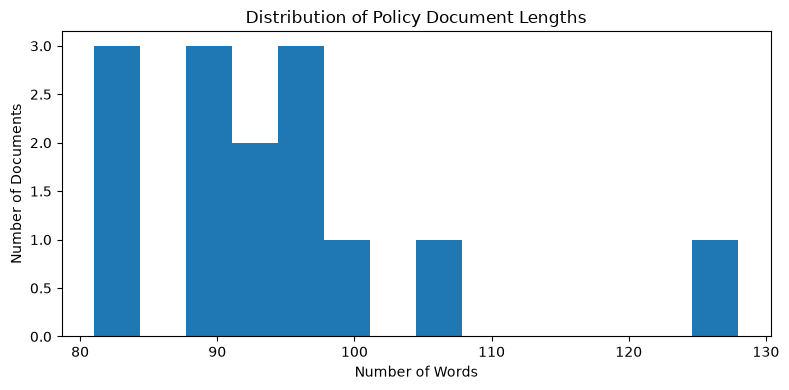

In [4]:
# 1. Locate the policy documents file
PROJECT_DIR = Path.cwd()

possible_files = [
    PROJECT_DIR / "waste_policy_documents.csv",
    PROJECT_DIR / "waste_policy_documents.json",
    PROJECT_DIR / "data" / "waste_policy_documents.csv",
    PROJECT_DIR / "data" / "waste_policy_documents.json",
]

policy_path = next(
    (path for path in possible_files if path.is_file()),
    None
)

# Search subfolders
if policy_path is None:
    matches = (
        list(PROJECT_DIR.rglob("waste_policy_documents.csv"))
        + list(PROJECT_DIR.rglob("waste_policy_documents.json"))
    )
    if matches:
        policy_path = matches[0]

if policy_path is None:
    raise FileNotFoundError(
        "Could not find waste_policy_documents.csv or "
        "waste_policy_documents.json. Check the file location."
    )

print("Policy file location:", policy_path)

# 2. Load the file according to its format
if policy_path.suffix.lower() == ".csv":
    policy_df = pd.read_csv(policy_path)

elif policy_path.suffix.lower() == ".json":
    with open(policy_path, "r", encoding="utf-8") as file:
        policy_data = json.load(file)

    # Handle common JSON document organizations
    if isinstance(policy_data, list):
        policy_df = pd.json_normalize(policy_data)

    elif isinstance(policy_data, dict):
        if isinstance(policy_data.get("documents"), list):
            policy_df = pd.json_normalize(policy_data["documents"])
        elif isinstance(policy_data.get("policies"), list):
            policy_df = pd.json_normalize(policy_data["policies"])
        else:
            # Treat a single JSON object as one record
            policy_df = pd.json_normalize(policy_data)

    else:
        raise ValueError("Unexpected JSON structure in the policy file.")

print("\nNumber of documents/records:", len(policy_df))
print("Number of columns:", len(policy_df.columns))

# 3. understand document organization
print("\nColumn names:")
print(policy_df.columns.tolist())

print("\nFirst five records:")
display(policy_df.head())

print("\nData types:")
print(policy_df.dtypes)

print("\nMissing values per column:")
print(policy_df.isnull().sum())

# 4. inspect the original JSON structure, if applicable
if policy_path.suffix.lower() == ".json":
    print("\nOriginal JSON structure:")
    if isinstance(policy_data, dict):
        print("Top-level keys:", list(policy_data.keys()))
    elif isinstance(policy_data, list):
        print("Top-level structure: list")
        if policy_data:
            print("First item type:", type(policy_data[0]).__name__)
            if isinstance(policy_data[0], dict):
                print("First item's keys:", list(policy_data[0].keys()))

# 5. Identify likely text fields
text_columns = policy_df.select_dtypes(
    include=["object", "string"]
).columns.tolist()

print("\nText-like columns:", text_columns)

# Find fields that contain substantial policy language
for col in text_columns:
    non_null = policy_df[col].dropna().astype(str)

    if not non_null.empty:
        average_length = non_null.str.len().mean()
        print(
            f"\nColumn: {col}"
            f"\n  Non-empty values: {len(non_null)}"
            f"\n  Average character length: {average_length:.1f}"
            f"\n  Example: {non_null.iloc[0][:300]}"
        )

# 6. Explore vocabulary from text fields
# Combine text-like fields so titles, descriptions, and policy text
# can all contribute to the vocabulary.
if text_columns:
    text_data = (
        policy_df[text_columns]
        .fillna("")
        .astype(str)
        .agg(" ".join, axis=1)
    )

    all_text = " ".join(text_data).lower()
    words = re.findall(r"\b[a-zA-Z]+\b", all_text)
    word_counts = Counter(words)

    print("\nLanguage statistics:")
    print("Total word tokens:", len(words))
    print("Unique words:", len(set(words)))

    print("\n20 most frequent words:")
    display(pd.DataFrame(
        word_counts.most_common(20),
        columns=["Word", "Frequency"]
    ))

    # Document length in words
    document_lengths = text_data.apply(
        lambda text: len(re.findall(r"\b[a-zA-Z]+\b", text))
    )

    print("\nDocument length statistics (words):")
    display(document_lengths.describe().to_frame("Word Count"))

    # Plot document lengths
    if len(document_lengths) > 0:
        document_lengths.plot(
            kind="hist",
            bins=min(20, max(1, len(document_lengths))),
            figsize=(8, 4)
        )
        plt.title("Distribution of Policy Document Lengths")
        plt.xlabel("Number of Words")
        plt.ylabel("Number of Documents")
        plt.tight_layout()
        plt.show()

else:
    print(
        "\nNo text-like columns were identified. "
        "Inspect the original file structure to locate the policy text."
    )

### 1.3. Create Data Pipelines

In [7]:
# Run this code to setup the images properly into train, validation, and test sets
# Set your data directory path - update this with your actual path
import pathlib
data_dir = pathlib.Path.cwd() / "data/realwaste-main" / "RealWaste"

# Parameters
BATCH_SIZE = 32
IMG_HEIGHT = 224
IMG_WIDTH = 224

# Calculate the total number of classes automatically from the directory structure
num_classes = len([item for item in data_dir.glob('*') if item.is_dir()])
print(f"Number of classes: {num_classes}")

# List all class folders
class_names = sorted([item.name for item in data_dir.glob('*') if item.is_dir()])
print(f"Class names: {class_names}")

# Count all images
image_count = len(list(data_dir.glob('*/*.jpg'))) + len(list(data_dir.glob('*/*.png')))
print(f"Total images found: {image_count}")

# Create a dataset using tf.keras.utils.image_dataset_from_directory
# This will automatically split the data into training and validation sets
train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,  # 20% for validation
    subset="training",
    seed=42,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    label_mode='categorical',  # For one-hot encoded labels
    shuffle=True
)

validation_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,  # 20% for validation
    subset="validation",
    seed=42,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    label_mode='categorical',  # For one-hot encoded labels
    shuffle=True
)

# Create a separate test dataset by taking part of the validation set
# First, let's get the number of batches in the validation set
val_batches = tf.data.experimental.cardinality(validation_ds)
test_dataset = validation_ds.take(val_batches // 2)
validation_ds = validation_ds.skip(val_batches // 2)

print(f"Number of training batches: {tf.data.experimental.cardinality(train_ds)}")
print(f"Number of validation batches: {tf.data.experimental.cardinality(validation_ds)}")
print(f"Number of test batches: {tf.data.experimental.cardinality(test_dataset)}")

# Configure dataset for performance
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
validation_ds = validation_ds.cache().prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.cache().prefetch(buffer_size=AUTOTUNE)

Number of classes: 9
Class names: ['Cardboard', 'Food Organics', 'Glass', 'Metal', 'Miscellaneous Trash', 'Paper', 'Plastic', 'Textile Trash', 'Vegetation']
Total images found: 4752
Found 4752 files belonging to 9 classes.
Using 3802 files for training.
Found 4752 files belonging to 9 classes.
Using 950 files for validation.
Number of training batches: 119
Number of validation batches: 15
Number of test batches: 15


In [ ]:
# TODO: - Tokenization
# - Text cleaning
# - Split data into train and test
# - Create embeddings/features

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline

# 1. we inspect the dataset already loaded in an earlier cell.
# We reuse waste_df instead of loading the CSV again.

print("Available columns:", waste_df.columns.tolist())

# Identify the columns containing text descriptions and labels.
# This allows the code to work even if the column names differ slightly.
description_candidates = [
    col for col in waste_df.columns
    if any(word in col.lower() for word in ["description", "text", "sentence"])
]

category_candidates = [
    col for col in waste_df.columns
    if any(word in col.lower() for word in ["category", "label", "class", "waste_type"])
]

if not description_candidates or not category_candidates:
    raise ValueError(
        "Could not identify the description and category columns. "
        "Check waste_df.columns.tolist() and set the column names manually."
    )

TEXT_COLUMN = description_candidates[0]
LABEL_COLUMN = category_candidates[0]

print("Text column:", TEXT_COLUMN)
print("Label column:", LABEL_COLUMN)

# 2. Remove rows without a description or category.
# Missing labels cannot be used for supervised classification.
text_df = waste_df[[TEXT_COLUMN, LABEL_COLUMN]].copy()
text_df = text_df.dropna(subset=[TEXT_COLUMN, LABEL_COLUMN])

# Convert descriptions to strings and remove empty descriptions.
text_df[TEXT_COLUMN] = text_df[TEXT_COLUMN].astype(str).str.strip()
text_df = text_df[text_df[TEXT_COLUMN] != ""]

print("\nRows after removing missing/empty values:", len(text_df))

# 3. Clean the text.
# - Convert text to lowercase for consistency.
# - Remove URLs.
# - Remove punctuation and special characters.
# - Keep letters, numbers, and spaces.
def clean_text(text):
    text = text.lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

text_df["clean_description"] = text_df[TEXT_COLUMN].apply(clean_text)

# Remove descriptions that became empty after cleaning.
text_df = text_df[text_df["clean_description"] != ""]

print("\nExample before cleaning:")
print(text_df[TEXT_COLUMN].iloc[0])

print("\nExample after cleaning:")
print(text_df["clean_description"].iloc[0])

# 4. Tokenization.
# Split each cleaned description into individual words (tokens).
text_df["tokens"] = text_df["clean_description"].apply(str.split)

print("\nExample tokens:")
print(text_df["tokens"].iloc[0])

# 5. Separate the input text (X) from the target labels (y).
X = text_df["clean_description"]
y = text_df[LABEL_COLUMN]

# 6. Split into training and testing data.
# Stratification preserves category proportions where possible.
# A fixed random_state makes the split reproducible.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining examples:", len(X_train))
print("Testing examples:", len(X_test))

# 7. Convert text into numerical features using TF-IDF.
# The vectorizer learns vocabulary and IDF weights from training text only.
# Unseen test data is transformed using the training vocabulary.
tfidf_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),  # Use individual words and two-word phrases
    max_features=10000
)

X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

print("\nTraining feature matrix shape:", X_train_tfidf.shape)
print("Testing feature matrix shape:", X_test_tfidf.shape)
print("Number of learned features:", len(tfidf_vectorizer.get_feature_names_out()))

# 8. Inspect some learned features.
print("\nSample TF-IDF features:")
print(tfidf_vectorizer.get_feature_names_out()[:20])

Available columns: ['description', 'category', 'disposal_instruction', 'common_confusion', 'material_composition']
Text column: description
Label column: category

Rows after removing missing/empty values: 5000

Example before cleaning:
soiled silver tablecloth

Example after cleaning:
soiled silver tablecloth

Example tokens:
['soiled', 'silver', 'tablecloth']

Training examples: 4000
Testing examples: 1000

Training feature matrix shape: (4000, 5300)
Testing feature matrix shape: (1000, 5300)
Number of learned features: 5300

Sample TF-IDF features:
['aerosol' 'aerosol can' 'aluminum' 'aluminum can' 'aluminum foil' 'apple'
 'apple core' 'appliance' 'appliance box' 'artisanal' 'artisanal aluminum'
 'artisanal avocado' 'artisanal baby' 'artisanal banana'
 'artisanal battery' 'artisanal bed' 'artisanal branches'
 'artisanal bread' 'artisanal bush' 'artisanal cardboard']


In [9]:
# TODO: Prepare documents for RAG
# - Document preprocessing
# - Create embeddings for retrieval

# 1. Inspect the policy documents loaded in the previous cell.
# Reuse the existing DataFrame; do not load the JSON again.

print("Policy dataset shape:", policy_df.shape)
print("Available columns:", policy_df.columns.tolist())

# 2. Clean the document text.
# Preserve meaningful wording and policy instructions.
# Remove excess whitespace and empty lines.

def clean_document(text):
    text = str(text)
    text = re.sub(r'\r\n?', '\n', text)
    text = re.sub(r'[ \t]+', ' ', text)
    text = re.sub(r'\n{3,}', '\n\n', text)
    return text.strip()

policy_df = policy_df.dropna(subset=["document_text"]).copy()
policy_df["clean_text"] = policy_df["document_text"].apply(clean_document)

# Remove documents that contain no usable text.
policy_df = policy_df[policy_df["clean_text"] != ""].reset_index(drop=True)

print("\nNumber of usable policy documents:", len(policy_df))
print("\nExample cleaned document:")
print(policy_df["clean_text"].iloc[0][:500])

# 3. Split documents into smaller chunks.
# Smaller chunks help retrieval return the relevant section
# instead of an entire long policy document.
#
# We use word-based chunks with a small overlap so important
# instructions near chunk boundaries are less likely to be lost.

CHUNK_SIZE = 150
CHUNK_OVERLAP = 30

def split_into_chunks(text, chunk_size=CHUNK_SIZE, overlap=CHUNK_OVERLAP):
    words = text.split()
    chunks = []
    start = 0

    while start < len(words):
        end = min(start + chunk_size, len(words))
        chunk = " ".join(words[start:end])

        if chunk.strip():
            chunks.append(chunk)

        if end == len(words):
            break

        start = end - overlap

    return chunks

# 4. Keep each chunk linked to its original policy metadata.
# Metadata helps us identify which policy a retrieved chunk came from.

document_chunks = []

for _, row in policy_df.iterrows():
    chunks = split_into_chunks(row["clean_text"])

    for chunk_number, chunk in enumerate(chunks):
        document_chunks.append({
            "policy_id": row.get("policy_id", None),
            "policy_type": row.get("policy_type", "Unknown"),
            "jurisdiction": row.get("jurisdiction", "Unknown"),
            "categories_covered": row.get("categories_covered", []),
            "effective_date": row.get("effective_date", None),
            "chunk_number": chunk_number,
            "text": chunk
        })

chunks_df = pd.DataFrame(document_chunks)

print("\nTotal document chunks:", len(chunks_df))
display(chunks_df.head())

# 5. Create semantic embeddings for retrieval.
# SentenceTransformer converts each text chunk into a numerical vector.
# Similar meanings should have nearby vectors, even when the wording differs.
#
# The first run may download the model if it is not already cached.

from sentence_transformers import SentenceTransformer

embedding_model = SentenceTransformer("all-MiniLM-L6-v2")

document_embeddings = embedding_model.encode(
    chunks_df["text"].tolist(),
    convert_to_numpy=True,
    normalize_embeddings=True,
    show_progress_bar=True
)

print("\nEmbedding matrix shape:", document_embeddings.shape)
print("Number of embedded chunks:", len(document_embeddings))
print("Embedding vector size:", document_embeddings.shape[1])

Policy dataset shape: (14, 6)
Available columns: ['policy_id', 'policy_type', 'categories_covered', 'effective_date', 'document_text', 'jurisdiction']

Number of usable policy documents: 14

Example cleaned document:
TEXTILE RECYCLING GUIDELINES

Acceptable Items:
- Clean clothing (all conditions)
- Towels, sheets, and linens
- Fabric scraps
- Curtains and cloth napkins
- Handbags and backpacks made of fabric
- Soft toys and stuffed animals

Non-Acceptable Items:
- Wet or moldy textiles
- Heavily soiled items
- Carpets and rugs
- Footwear
- Items with significant non-textile parts

Collection Method:
Place items in dedicated textile recycling bins or donate to local thrift stores.

Preparation Instructions:


Total document chunks: 14


,policy_id,policy_type,jurisdiction,categories_covered,effective_date,chunk_number,text
0,1,Textile Trash Recycling Guidelines,Metro City,[Textile Trash],2023-11-04,0,TEXTILE RECYCLING GUIDELINES Acceptable Items:...
1,2,Glass Recycling Guidelines,Metro City,[Glass],2023-01-24,0,GLASS RECYCLING GUIDELINES Acceptable Items: -...
2,3,Food Organics Recycling Guidelines,Metro City,[Food Organics],2023-05-08,0,FOOD ORGANICS RECYCLING GUIDELINES Acceptable ...
3,4,Plastic Recycling Guidelines,Metro City,[Plastic],2023-04-05,0,PLASTIC RECYCLING GUIDELINES Acceptable Items:...
4,5,Vegetation Recycling Guidelines,Metro City,[Vegetation],2023-12-04,0,VEGETATION RECYCLING GUIDELINES Acceptable Ite...


c:\Users\kevin\anaconda3\envs\vinohealth\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Batches: 100%|██████████| 1/1 [00:00<00:00,  1.11it/s]


Embedding matrix shape: (14, 384)
Number of embedded chunks: 14
Embedding vector size: 384


### Part 2: Waste Material Classification with CNN

In this section, I build a CNN model to classify waste materials from images

### 2.1. Preprocess Images

Classes: ['Cardboard', 'Food Organics', 'Glass', 'Metal', 'Miscellaneous Trash', 'Paper', 'Plastic', 'Textile Trash', 'Vegetation']
Number of classes: 9

Image preprocessing completed.
Image batch shape: (32, 224, 224, 3)
Label batch shape: (32, 9)
Pixel value range: -1.0 to 1.0


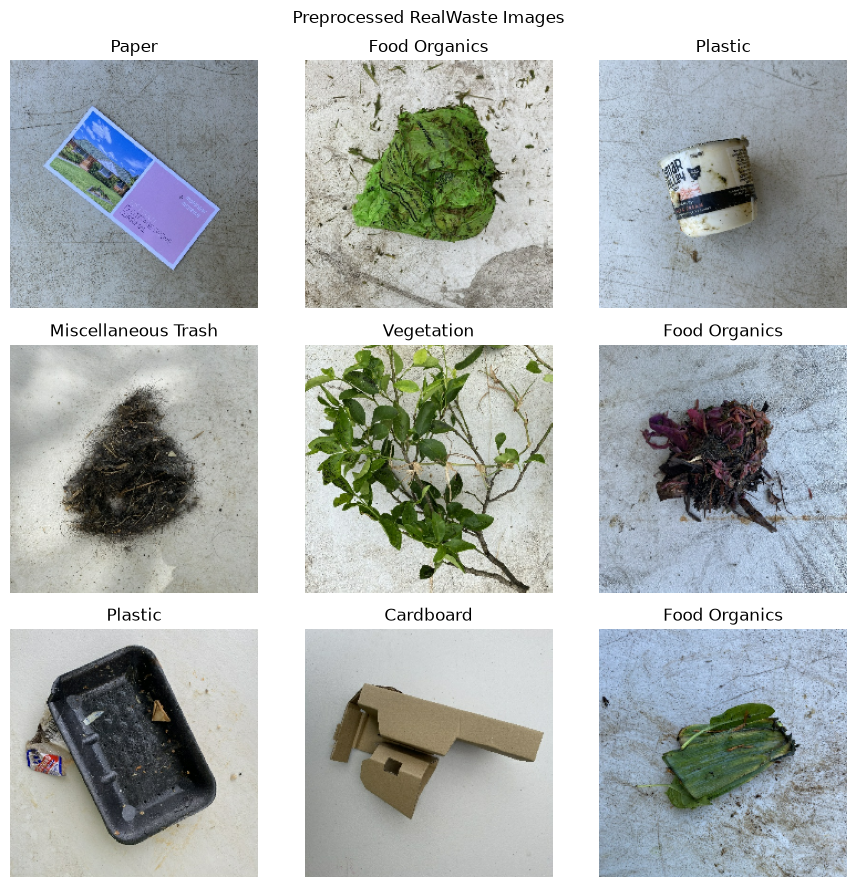

In [10]:
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# Confirm that the datasets created earlier are available.
print("Classes:", class_names)
print("Number of classes:", num_classes)

# MobileNetV2 expects image pixel values to be scaled
# from the range [0, 255] to the range [-1, 1].
# image_dataset_from_directory has already resized the images
# to 224 x 224 pixels.

def preprocess_images(images, labels):
    # Apply MobileNetV2's required pixel preprocessing.
    images = preprocess_input(images)
    return images, labels

# Create preprocessed versions of the existing datasets.
# We use new variable names so that rerunning this cell
# does not preprocess already-preprocessed images a second time.

AUTOTUNE = tf.data.AUTOTUNE

train_ds_preprocessed = train_ds.map(
    preprocess_images,
    num_parallel_calls=AUTOTUNE
).prefetch(buffer_size=AUTOTUNE)

validation_ds_preprocessed = validation_ds.map(
    preprocess_images,
    num_parallel_calls=AUTOTUNE
).prefetch(buffer_size=AUTOTUNE)

test_ds_preprocessed = test_dataset.map(
    preprocess_images,
    num_parallel_calls=AUTOTUNE
).prefetch(buffer_size=AUTOTUNE)

print("\nImage preprocessing completed.")

# Inspect one batch to confirm the image dimensions and labels.
for images, labels in train_ds_preprocessed.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print(
        "Pixel value range:",
        float(tf.reduce_min(images)),
        "to",
        float(tf.reduce_max(images))
    )

# Display a few preprocessed images.
# Reverse MobileNetV2 preprocessing for visualization only.
for images, labels in train_ds_preprocessed.take(1):
    display_images = (images[:9] + 1.0) / 2.0
    display_images = tf.clip_by_value(display_images, 0.0, 1.0)

    fig, axes = plt.subplots(3, 3, figsize=(9, 9))

    for i, ax in enumerate(axes.flat):
        if i < len(display_images):
            ax.imshow(display_images[i].numpy())
            class_index = int(tf.argmax(labels[i]).numpy())
            ax.set_title(class_names[class_index])
        ax.axis("off")

    plt.suptitle("Preprocessed RealWaste Images")
    plt.tight_layout()
    plt.show()

### 2.2. Implement CNN Model with Transfer Learning

In [11]:
# TODO: Select an appropriate base model and implement transfer learning
# - Choose from MobileNet, EfficientNet, etc.
# - Add custom classification layers for the 9 waste categories
# - Configure loss function and metrics

from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2

# 1. Load MobileNetV2 with pretrained ImageNet weights.
# include_top=False removes its original 1,000-class classifier.
# We will add our own classifier for the waste categories.

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# 2. Freeze the pretrained layers initially.
# This preserves the visual features learned from ImageNet
# while we train the new waste classification layers.

base_model.trainable = False

# 3. Build the classification model.
model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    # Extract visual features from each image.
    base_model,

    # Convert feature maps into a single feature vector.
    layers.GlobalAveragePooling2D(),

    # Dropout reduces over-reliance on individual neurons.
    layers.Dropout(0.3),

    # Predict a probability for each waste category.
    layers.Dense(
        num_classes,
        activation="softmax"
    )
])

# 4. Configure the model for multiclass classification.
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# 5. Display the model architecture and parameter counts.
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 9)              │        11,529 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,269,513 (8.66 MB)

 Trainable params: 11,529 (45.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)